In [2]:
import pandas as pd

import numpy as np
from scipy import stats

import seaborn as sns

In [8]:
data = pd.read_csv('datas/cardio.csv', sep=';')
data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


Анализ корреляции числовых признаков

In [11]:
numeric = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']
data[numeric].corr()

,age,height,weight,ap_hi,ap_lo
age,1.000000,-0.081515,0.053684,0.020764,0.017647
height,-0.081515,1.000000,0.290968,0.005488,0.006150
weight,0.053684,0.290968,1.000000,0.030702,0.043710
ap_hi,0.020764,0.005488,0.030702,1.000000,0.016086
ap_lo,0.017647,0.006150,0.043710,0.016086,1.000000


<Axes: >

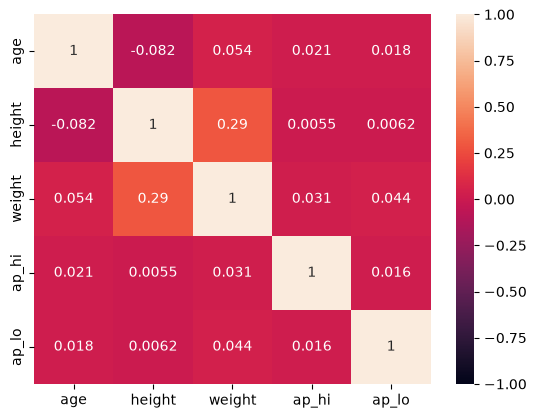

In [12]:
sns.heatmap(data[numeric].corr(), vmin=-1, vmax=1,annot=True )

статистическая значимость коэффициента корреляции

In [13]:
from scipy.stats import pearsonr, spearmanr, kendalltau

In [ ]:
pearsonr(data.weight, data.height) #p-value < 0.05 значит взаимосвязь между ростом и весом статистически значима

PearsonRResult(statistic=np.float64(0.2909678349914984), pvalue=np.float64(0.0))

In [ ]:
spearmanr(data.weight, data.cholesterol) #p-value < 0.05 значит взаимосвязь между весом и холстеролом статистически значима

SignificanceResult(statistic=np.float64(0.13790793370008902), pvalue=np.float64(2.984753794476824e-294))

In [17]:
kendalltau(data.weight, data.cholesterol) #p-value < 0.05 значит взаимосвязь между весом и холстеролом статистически значима

SignificanceResult(statistic=np.float64(0.11061576645010737), pvalue=np.float64(2.4466562782805854e-291))

In [ ]:
print(pearsonr(data.weight, data.ap_hi)) # связь между переменными слабая, но статистически значимая
print(pearsonr(data.height, data.ap_hi)) # не является статистически значимой

PearsonRResult(statistic=np.float64(0.030702208651581905), pvalue=np.float64(4.480599811218598e-16))
PearsonRResult(statistic=np.float64(0.005487764158405931), pvalue=np.float64(0.14652637424684156))


Анализ корреляций категориальных признаков

In [20]:
pd.crosstab(data.smoke, data.cardio)

cardio,0,1
smoke,,
0,31781,32050
1,3240,2929


<Axes: xlabel='cardio', ylabel='smoke'>

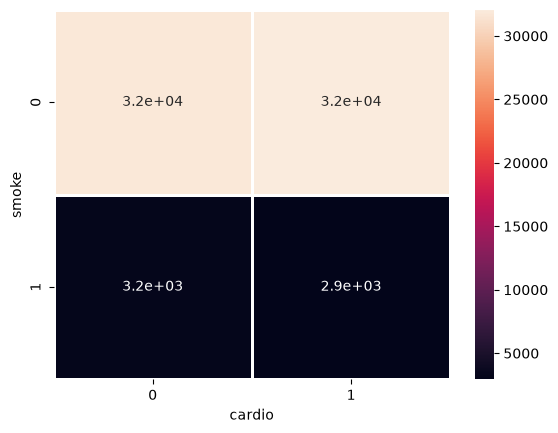

In [22]:
sns.heatmap(pd.crosstab(data.smoke, data.cardio), annot=True, linewidth=2, linecolor='white' )

In [24]:
pd.crosstab(data.smoke, data.cardio) / data.shape[0]

cardio,0,1
smoke,,
0,0.454014,0.457857
1,0.046286,0.041843


<Axes: xlabel='cardio', ylabel='smoke'>

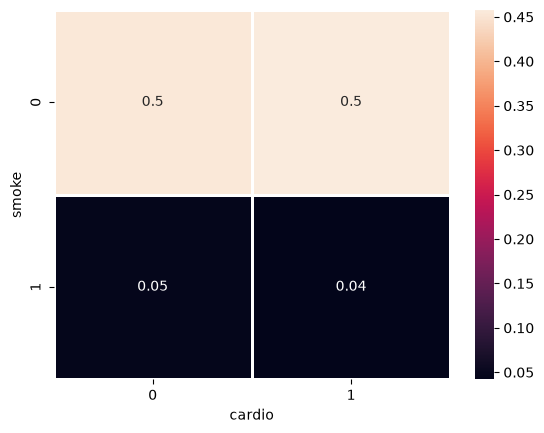

In [27]:
sns.heatmap((pd.crosstab(data.smoke, data.cardio) / data.shape[0]), annot=True, linewidth=2, linecolor='white', fmt='.1' )

Хи-квадрат

In [28]:
from scipy.stats import chi2_contingency

In [ ]:
chi2_contingency(pd.crosstab(data.smoke, data.cardio)) # cтатистически значима так как p-value < 0.05

Chi2ContingencyResult(statistic=np.float64(16.677916738748436), pvalue=np.float64(4.429362360507765e-05), dof=1, expected_freq=array([[31934.6493, 31896.3507],
       [ 3086.3507,  3082.6493]]))